# configuration & loadings

In [3]:
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "gvns").exists():
    PROJECT_ROOT = Path(__file__).parent.parent.parent.parent if '__file__' in locals() else Path.cwd().parent.parent.parent

print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\HP\Documents\GitHub\GVNS-implementation


In [17]:
# load data and model
DATA_PATH = PROJECT_ROOT / "gvns" / "ls_data" / "learning_dataset.csv"
MODEL_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_delta_regressor.pkl"
FEATURES_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_features.json"

model = joblib.load(MODEL_PATH)

with open(FEATURES_PATH) as f:
    feature_names = json.load(f)

df = pd.read_csv(DATA_PATH)
df.head()

,instance_name,gvns_iter,neigh_id,n_customers,n_vehicles,horizon,sync_ratio,avg_tw_width,min_tw_width,tw_tightness,...,PV,pen_ratio,penT_ratio,penS_ratio,k,k_norm,delta,elapsed,strategy,rel_delta
0,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,10,9.999888e-07,0.000000,9.999888e-07,0,0.0,9.999293e+05,0.021839,0,0.027776
1,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,12,2.143647e-05,0.000020,9.999771e-07,0,0.0,1.999635e+06,0.148822,0,0.057132
2,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,12,9.999873e-07,0.000000,9.999873e-07,0,0.0,3.372098e+02,0.001002,0,0.000010
3,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,13,9.999862e-07,0.000000,9.999862e-07,0,0.0,9.999777e+05,0.509428,0,0.030302
4,C102_30_15,1,0,30,10,1236.0,0.5,372.774194,45.0,0.301597,...,15,4.018982e-05,0.000039,9.999612e-07,0,0.0,1.999276e+06,0.771377,0,0.062477


In [6]:
# check 
assert "strategy" in df.columns
assert "rel_delta" in df.columns
assert set(feature_names).issubset(df.columns)

# Prediction table
prediction = expected improvement if that strategy is chosen (decision signal)

In [7]:
# 2 virtual actions per state 
X = df[feature_names].copy()

df["pred_rel_delta"] = model.predict(X)

we need to compare same state, same neigh

In [8]:
# pair FI and BI decisions
KEYS = [
    "instance_name",
    "gvns_iter",
    "neigh_id",
]

df_fi = df[df["strategy"] == 0].set_index(KEYS)
df_bi = df[df["strategy"] == 1].set_index(KEYS)

paired = df_fi.join(
    df_bi,
    lsuffix="_fi",
    rsuffix="_bi",
    how="inner"
)

In [9]:
# ML decision rule
# 1 if BI predicted better, 0 if FI predicted better
paired["ml_choice"] = (
    paired["pred_rel_delta_bi"] >
    paired["pred_rel_delta_fi"]
).astype(int)

In [10]:
# compute realized gains
paired["realized_ml"] = np.where(
    paired["ml_choice"] == 1,
    paired["rel_delta_bi"],
    paired["rel_delta_fi"]
)

# compute baselines 
paired["realized_fi"] = paired["rel_delta_fi"]
paired["realized_bi"] = paired["rel_delta_bi"]

# Comparison results

In [11]:
# global comparisons
summary = {
    "FI": paired["realized_fi"].mean(),
    "BI": paired["realized_bi"].mean(),
    "ML": paired["realized_ml"].mean(),
}

pd.Series(summary)

FI    0.003177
BI    0.008014
ML    0.009725
dtype: float64

In [16]:
# per-instance comparisons
inst_perf = paired.groupby("instance_name").agg(
    FI=("realized_fi", "mean"),
    BI=("realized_bi", "mean"),
    ML=("realized_ml", "mean"),
)

inst_perf.head()


,FI,BI,ML
instance_name,,,
C102_30_15,0.020270,0.070270,0.079291
C102_30_3,0.024150,0.035339,0.049636
C102_30_9,0.017248,0.027159,0.038421
C106_100_10,0.003344,0.007413,0.009079
C106_100_20,0.003047,0.007886,0.009456


In [13]:
# win rate analysis
wins = {
    "ML > FI": (inst_perf["ML"] > inst_perf["FI"]).mean(),
    "ML > BI": (inst_perf["ML"] > inst_perf["BI"]).mean(),
}

pd.Series(wins)

ML > FI    1.0
ML > BI    1.0
dtype: float64

C:\Users\HP\AppData\Local\Temp\ipykernel_3816\4159977065.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


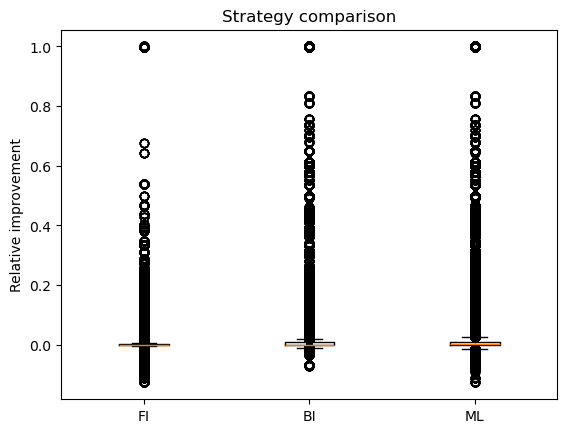

In [14]:
# distribution plots 
plt.boxplot(
    [paired["realized_fi"], paired["realized_bi"], paired["realized_ml"]],
    labels=["FI", "BI", "ML"]
)
plt.ylabel("Relative improvement")
plt.title("Strategy comparison")
plt.show()

In [15]:
# decision behavior analysis
paired["ml_choice"].value_counts(normalize=True)

ml_choice
1    0.663549
0    0.336451
Name: proportion, dtype: float64